# 02ahycom: ocean currents for the Bering Strait, year 2000

PF9, step 3. Downloads HYCOM GOFS 3.1 currents and water temperature for our window, from the HYCOM data server (free, no login, no Copernicus).

1. **Probe:** downloads ONE snapshot, reports the time taken and the size, and checks the longitudes around the 180° meridian.
2. **Download:** the chosen years and months, one snapshot every few days (00:00 UTC), trimmed to the top `MAX_DEPTH_M` metres and saved one file per day in `data/raw/hycom/`. Files already there are skipped, so it can be stopped and started again.
3. **Estimate:** from the measured speed, how long and how big the full plan would be.

Part 1 of 4 of the remaining download: year **2000** only (February, May, August, November; 61 snapshots, about 1.5 hours). Same code as 02hycomdownload. Safe to stop (interrupt the kernel) and run again later: files already saved are skipped.

Only reanalysis years (1994 to 2015) for now. The later years come from a different HYCOM system and will be added once this works.

The raw files can be deleted after the project: the page only needs the small monthly means made from them later.

## Section 0. Settings

Lines marked `# <-` can be changed.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
OUT_DIR = PROJECT_DIR / "data" / "raw" / "hycom"

YEARS = [2000]  # <- the year this notebook downloads
PLAN_YEARS = [1995, 2000, 2005, 2010, 2015, 2020, 2023]  # <- only used for the size and time estimate
MONTHS = [2, 5, 8, 11]  # <- February (winter ice), May (break-up), August (open water), November (freeze-up)
DAY_STEP = 2  # <- one snapshot every DAY_STEP days (1 = every day)
HOUR = 0  # <- snapshot hour in UTC (the reanalysis has 0, 3, 6, ... 21)

NORTH = 72.0  # <- window, degrees north
SOUTH = 62.0  # <- window, degrees north
WEST = 175.0  # <- window, degrees east (Chukotka side)
EAST = 205.0  # <- window, degrees east, 205 = 155°W (Alaska side)
MAX_DEPTH_M = 100  # <- keep only depth levels down to this depth (the shelf is about 50 m deep)
VARIABLES = ["water_u", "water_v", "water_temp"]  # <- eastward current, northward current, temperature

BASE_URL = "https://ncss.hycom.org/thredds/ncss"  # <- HYCOM subsetting service
REANALYSIS_PATH = "GLBv0.08/expt_53.X/data/{year}"  # <- reanalysis, one dataset per year, 1994 to 2015
TIMEOUT_S = 300  # <- give up on one request after this many seconds
RETRIES = 3  # <- tries per request

## Section 1. Libraries

In [2]:
import time
import datetime as dt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import matplotlib.pyplot as plt

OUT_DIR.mkdir(parents=True, exist_ok=True)
TMP_DIR = OUT_DIR / "_tmp"
TMP_DIR.mkdir(exist_ok=True)


def snapshot_times(years, months, day_step, hour):
    out = []
    for y in years:
        for m in months:
            day = dt.datetime(y, m, 1, hour)
            while day.month == m:
                out.append(day)
                day = day + dt.timedelta(days=day_step)
    return out


def request_url(when, west, east):
    path = REANALYSIS_PATH.format(year=when.year)
    var_part = "&".join(f"var={v}" for v in VARIABLES)
    return f"{BASE_URL}/{path}?{var_part}&north={NORTH}&south={SOUTH}&west={west}&east={east}&horizStride=1&time={when:%Y-%m-%dT%H:%M:%SZ}&addLatLon=true&accept=netcdf4"


def fetch(url, dest):
    last_error = None
    for attempt in range(1, RETRIES + 1):
        try:
            t0 = time.perf_counter()
            with requests.get(url, timeout=TIMEOUT_S, stream=True) as r:
                if r.status_code != 200:
                    last_error = f"HTTP {r.status_code}: {r.text[:200]}"
                    if r.status_code in (400, 404):
                        break
                    continue
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            return time.perf_counter() - t0, dest.stat().st_size, None
        except requests.RequestException as e:
            last_error = str(e)
            time.sleep(5 * attempt)
    return None, 0, last_error


def open_trim(path):
    ds = xr.open_dataset(path, engine="h5netcdf")
    if "depth" in ds.dims:
        ds = ds.sel(depth=ds.depth[ds.depth <= MAX_DEPTH_M])
    lon_name = "lon" if "lon" in ds.coords else "longitude"
    ds = ds.assign_coords({lon_name: ds[lon_name] % 360}).sortby(lon_name)
    return ds.load()


def save(ds, dest):
    enc = {v: {"zlib": True, "complevel": 4} for v in ds.data_vars}
    ds.to_netcdf(dest, engine="h5netcdf", encoding=enc)
    ds.close()

## Section 2. Probe: one snapshot

Tries the whole window in one request (175°E to 205°E). If the server refuses longitudes past 180, it asks for two pieces (175 to 180, and -180 to -155) and joins them. The way that works is remembered for Section 3.

In [3]:
probe_time = snapshot_times(YEARS[:1], MONTHS[:1], DAY_STEP, HOUR)[0]
print("Probe snapshot:", probe_time)

lon_mode = None
probe_parts = []
secs, size, err = fetch(request_url(probe_time, WEST, EAST), TMP_DIR / "probe_whole.nc")
if err is None:
    ds_try = open_trim(TMP_DIR / "probe_whole.nc")
    lon_try = ds_try["lon"] if "lon" in ds_try.coords else ds_try["longitude"]
    span = float(lon_try.max() - lon_try.min())
    print("One request: OK,", round(size / 1e6, 2), "MB in", round(secs, 1), "s; longitude span", round(span, 1), "degrees")
    if span > (EAST - WEST) * 0.9:
        lon_mode = "whole"
        probe_parts = [(secs, size)]
        probe = ds_try
else:
    print("One request refused:", err)

if lon_mode is None:
    s1, z1, e1 = fetch(request_url(probe_time, WEST, 180.0), TMP_DIR / "probe_a.nc")
    s2, z2, e2 = fetch(request_url(probe_time, -180.0, EAST - 360), TMP_DIR / "probe_b.nc")
    assert e1 is None and e2 is None, f"Both ways failed: {e1} / {e2}"
    lon_mode = "split"
    probe_parts = [(s1, z1), (s2, z2)]
    a = open_trim(TMP_DIR / "probe_a.nc")
    b = open_trim(TMP_DIR / "probe_b.nc")
    lon_name = "lon" if "lon" in a.coords else "longitude"
    probe = xr.concat([a, b], dim=lon_name).sortby(lon_name).drop_duplicates(lon_name)
    print("Two requests: OK,", round((z1 + z2) / 1e6, 2), "MB in", round(s1 + s2, 1), "s")

probe_secs = sum(p[0] for p in probe_parts)
probe_mb = sum(p[1] for p in probe_parts) / 1e6
print("Longitude mode:", lon_mode)
print(probe)

Probe snapshot: 2000-02-01 00:00:00
One request: OK, 0.2 MB in 96.7 s; longitude span 5.0 degrees
Two requests: OK, 1.69 MB in 13.6 s
Longitude mode: split
<xarray.Dataset> Size: 23MB
Dimensions:     (time: 1, depth: 20, lat: 251, lon: 376)
Coordinates:
  * time        (time) datetime64[ns] 8B 2000-02-01T12:00:00
  * depth       (depth) float64 160B 0.0 2.0 4.0 6.0 ... 70.0 80.0 90.0 100.0
  * lat         (lat) float64 2kB 62.0 62.04 62.08 62.12 ... 71.92 71.96 72.0
  * lon         (lon) float64 3kB 175.0 175.0 175.1 175.2 ... 204.8 204.9 205.0
Data variables:
    water_u     (time, depth, lat, lon) float32 8MB nan nan ... -0.027 -0.028
    water_v     (time, depth, lat, lon) float32 8MB nan nan nan ... 0.053 0.045
    water_temp  (time, depth, lat, lon) float32 8MB nan nan nan ... -1.517 -1.53
Attributes: (12/14)
    classification_level:      UNCLASSIFIED
    distribution_statement:    Approved for public release. Distribution unli...
    downgrade_date:            not applicable
   

Longitudes: 174.96 to 204.96 ( 376 cells )
Latitudes: 62.0 to 72.0 ( 251 cells )
Duplicate longitudes: 0
Depth levels kept (m): [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0]
Surface speed: median 0.043 m/s, 95th percentile 0.176 m/s


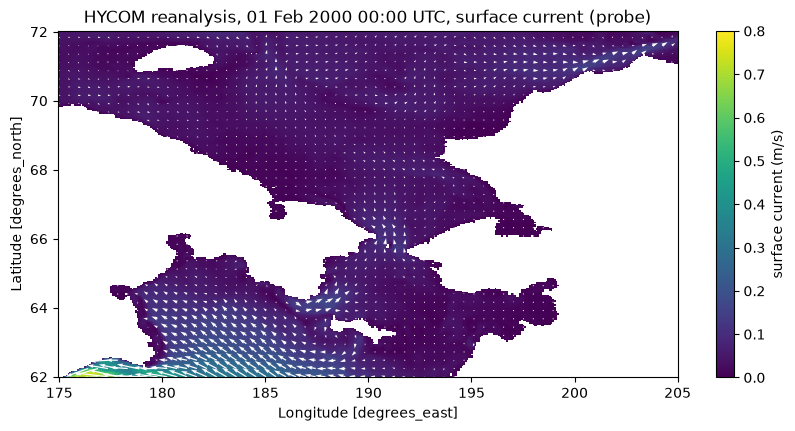

In [4]:
lon_name = "lon" if "lon" in probe.coords else "longitude"
lat_name = "lat" if "lat" in probe.coords else "latitude"
print("Longitudes:", round(float(probe[lon_name].min()), 2), "to", round(float(probe[lon_name].max()), 2), "(", probe.sizes[lon_name], "cells )")
print("Latitudes:", round(float(probe[lat_name].min()), 2), "to", round(float(probe[lat_name].max()), 2), "(", probe.sizes[lat_name], "cells )")
print("Duplicate longitudes:", int(probe[lon_name].to_index().duplicated().sum()))
print("Depth levels kept (m):", [float(d) for d in probe["depth"].values])

surf = probe.isel(time=0, depth=0) if "time" in probe.dims else probe.isel(depth=0)
speed = np.hypot(surf["water_u"], surf["water_v"])
print("Surface speed: median", round(float(speed.median()), 3), "m/s, 95th percentile", round(float(speed.quantile(0.95)), 3), "m/s")

fig, ax = plt.subplots(figsize=(10, 4.5))
speed.plot(ax=ax, x=lon_name, y=lat_name, cmap="viridis", vmin=0, vmax=0.8, cbar_kwargs={"label": "surface current (m/s)"})
step = 6
q = surf.isel({lat_name: slice(None, None, step), lon_name: slice(None, None, step)})
ax.quiver(q[lon_name], q[lat_name], q["water_u"], q["water_v"], color="white", scale=12, width=0.002)
ax.set_title(f"HYCOM reanalysis, {probe_time:%d %b %Y %H:%M} UTC, surface current (probe)")
plt.show()

## Section 3. Download the chosen years

One file per snapshot, `hycom_YYYYMMDD.nc`, trimmed to the top `MAX_DEPTH_M` metres. Existing files are skipped. A failed snapshot is listed at the end and can be retried by running this section again.

In [5]:
times = [t for t in snapshot_times(YEARS, MONTHS, DAY_STEP, HOUR) if t.year <= 2015]
skipped_years = sorted({y for y in YEARS if y > 2015})
if skipped_years:
    print("Not yet supported (analysis years):", skipped_years)
print("Snapshots to get:", len(times))

log = []
failed = []
t_start = time.perf_counter()
for i, when in enumerate(times):
    dest = OUT_DIR / f"hycom_{when:%Y%m%d}.nc"
    if dest.exists():
        continue
    if lon_mode == "whole":
        s, z, e = fetch(request_url(when, WEST, EAST), TMP_DIR / "part_a.nc")
        parts_ok = e is None
        secs_i = s or 0
        mb_i = z / 1e6
    else:
        s1, z1, e1 = fetch(request_url(when, WEST, 180.0), TMP_DIR / "part_a.nc")
        s2, z2, e2 = fetch(request_url(when, -180.0, EAST - 360), TMP_DIR / "part_b.nc")
        parts_ok = e1 is None and e2 is None
        e = e1 or e2
        secs_i = (s1 or 0) + (s2 or 0)
        mb_i = (z1 + z2) / 1e6
    if not parts_ok:
        failed.append((when, e))
        print(f"{when:%Y-%m-%d} FAILED: {e}")
        continue
    if lon_mode == "whole":
        ds = open_trim(TMP_DIR / "part_a.nc")
    else:
        a = open_trim(TMP_DIR / "part_a.nc")
        b = open_trim(TMP_DIR / "part_b.nc")
        ds = xr.concat([a, b], dim=lon_name).sortby(lon_name).drop_duplicates(lon_name)
    save(ds, dest)
    log.append({"time": when, "seconds": secs_i, "downloaded_mb": mb_i, "saved_mb": dest.stat().st_size / 1e6})
    done = len(log)
    elapsed = time.perf_counter() - t_start
    left = (len(times) - i - 1) * elapsed / done
    print(f"{when:%Y-%m-%d}  {secs_i:5.1f} s  {mb_i:5.1f} MB  ({done} done, about {left / 60:.0f} min left)")

print("Finished in", round((time.perf_counter() - t_start) / 60, 1), "min;", len(log), "new files,", len(failed), "failed")

Snapshots to get: 62
2000-02-25   85.6 s    1.5 MB  (1 done, about 70 min left)
2000-05-25   65.6 s    1.9 MB  (2 done, about 43 min left)
2000-05-27  124.8 s    2.0 MB  (3 done, about 51 min left)
2000-05-29   78.4 s    2.0 MB  (4 done, about 48 min left)
2000-05-31   39.6 s    2.0 MB  (5 done, about 41 min left)
Finished in 6.6 min; 5 new files, 0 failed


## Section 4. Speed, size and the estimate for the full plan

In [6]:
log_df = pd.DataFrame(log)
files = sorted(OUT_DIR.glob("hycom_*.nc"))
on_disk_mb = sum(f.stat().st_size for f in files) / 1e6
print("Files in data/raw/hycom:", len(files), "using", round(on_disk_mb), "MB")

if len(log_df):
    sec_per = log_df["seconds"].mean()
    mb_per = log_df["saved_mb"].mean()
    down_per = log_df["downloaded_mb"].mean()
    print("Per snapshot this run:", round(sec_per, 1), "s,", round(down_per, 1), "MB downloaded,", round(mb_per, 1), "MB saved")
else:
    sec_per = probe_secs
    mb_per = probe_mb
    print("No new downloads this run; using the probe:", round(sec_per, 1), "s and", round(mb_per, 1), "MB per snapshot")

plan_n = len(snapshot_times(PLAN_YEARS, MONTHS, DAY_STEP, HOUR))
print("Full plan:", len(PLAN_YEARS), "years x", len(MONTHS), "months, every", DAY_STEP, "days =", plan_n, "snapshots")
print("Estimated time for the full plan:", round(plan_n * sec_per / 3600, 1), "hours")
print("Estimated disk space for the full plan:", round(plan_n * mb_per / 1000, 2), "GB")
if failed:
    print("Failed snapshots (run Section 3 again to retry):", [f"{t:%Y-%m-%d}" for t, _ in failed])
log_df

Files in data/raw/hycom: 123 using 378 MB
Per snapshot this run: 78.8 s, 1.9 MB downloaded, 2.7 MB saved
Full plan: 7 years x 4 months, every 2 days = 429 snapshots
Estimated time for the full plan: 9.4 hours
Estimated disk space for the full plan: 1.14 GB


,time,seconds,downloaded_mb,saved_mb
0,2000-02-25,85.555688,1.504770,1.966620
1,2000-05-25,65.608740,1.868802,2.692555
2,2000-05-27,124.789669,1.951484,2.867970
3,2000-05-29,78.411419,1.956432,2.888962
4,2000-05-31,39.576114,1.977434,2.921629


___
**END**